In [3]:
# modules for research report
from datascience import *
import random
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')

# NYC Restaurant Inspections

The New York Department of Health and Mental Hygiene (DOHMH) provides a database of all violations, both confirmed and still being reviewed, from all restaurant and college cafeteria inspections done in the past three years. You can read more about the data and dataset [here](https://data.cityofnewyork.us/Health/DOHMH-New-York-City-Restaurant-Inspection-Results/43nn-pn8j/about_data).

The Restaurant health data you will be working with is split into 3 datasets: Grade, Location, and Violation. There is a detailed description of each dataset below.

**NB: You may not copy any public analyses of this dataset. Doing so will result in a zero.**

## Summary

> The three datasets (grade.csv, location.csv, and violation.csv) provide complementary information about restaurant health inspections. grade.csv contains inspection outcomes, including a numeric score, letter grade (A–C or pending), the date the grade was issued, and jurisdictional details like community board and council district. location.csv provides static information about each restaurant, such as its name, borough, cuisine type, and geographic coordinates (latitude and longitude). violation.csv details specific violations recorded during inspections, including the date, type of inspection, violation code, and whether the issue was critical. Together, these tables allow for a comprehensive analysis of restaurant performance, inspection history, and geographic distribution of violations.

## Data Description


A description of each table's variables is provided below:

`grade_2025_cleaned.csv`:
* `restaurant_id`: Unique ID for each restaurant, datatype = number.  
* `SCORE`: Total score for a particular inspection; Scores are updated based on adjudication results, datatype = number.
* `GRADE`: Grade associated with the inspection. Possible values include letter grades A-C, N=Not Yet Graded, Z=Grade Pending, P=Grade Pending on re-opening following another inspection that resulted in a colsure. Datatype = string。
* `GRADE DATE`: The date when the current grade was issued to the restaurant, datatype = timestamp。
* `RECORD DATE`: The date when the extract was run to produce this dataset, datatype = timestamp.
* `Community Board`: Unique ID for the community board, datatype = string.
* `Council District`: Unique ID for the council district, datatype = string.


`location_2025_cleaned.csv`:
* `DBA`: The name of the restaurant, datatype = string.
* `BORO` The borough in which the restaurant is located (1=Manhattan, 2=Bronx, 3=Brooklyn, 4=Queens, 5=Staten Island), datatype = string.
* `CUISINE DESCRIPT` Describes the restaurant cusine, optional field provided by orestaurant wner/manager, datatype = string.
* `Latitude` Latitude of the restaurant, datatype = number.
* `Longitude` Longitude of the restaurant, datatype = number.

`violation_2025_cleaned.csv`:
* `INSPECTION DATE`: Date of the inspection (Dates of 1/1/1900 mean the restaurant has not been inspected yet), datatype = timestamp.
* `INSPECTION TYPE`: Combination of the inspection program and the type of inspection performed, datatype = string.
* `VIOLATION CODE`: Violation code associated with a restaurant inspection, datatype = string.
* `CRITICAL FLAG`: Indicator of critical violation. Possible values include: Critical, Not Critical, Not Applicable. Critical values are most likely to contribute to food-borne illness. Datatype = string.
* `Community Board`: Unique ID for the community board, datatype = string.
* `Council District`: Unique ID for the council district, datatype = string.

## Inspiration

A variety of exploratory analyses, hypothesis tests, and predictions problems can tackled with this data. Here are a few ideas to get
you started:
1. How do inspection scores vary across different boroughs or cuisine types?
2. What’s the distribution of grades across all restaurants?
2. What are the most common critical violations, and do they vary by borough or cuisine?
3. Are critical violations more common in certain types of cuisine?
4. Do restaurants with lower grades (like B or C) get more violations than those with A grades?
6. Can we predict a restaurant’s grade (A, B, or C) based on its score, borough, and/or cuisine?


## Preview

The tables are loaded in the code cells below. Take some time to explore them!

In [4]:
# load the grade data
grade_data = Table.read_table('grade_2025_cleaned.csv')
grade_data

restaurant_id,SCORE,GRADE,GRADE DATE,Community Board,Council District
50061295,12,A,04/16/2024,109,7
50113299,9,A,10/07/2024,503,51
50130511,23,Z,09/05/2025,301,34
41005529,13,A,03/08/2022,112,10
50117590,11,A,10/08/2024,318,46
50070079,12,A,11/15/2024,104,3
50071517,11,A,04/15/2025,318,46
40884510,12,A,08/19/2022,108,5
50101410,12,A,04/25/2023,404,21
50108971,13,A,06/28/2024,308,35


In [5]:
# load the location data
location_data =Table.read_table('location_2025_cleaned.csv')
location_data

restaurant_id,DBA,BORO,CUISINE DESCRIPTION,Latitude,Longitude
30075445,MORRIS PARK BAKE SHOP,Bronx,Bakery Products/Desserts,40.8482,-73.856
30191841,D.J. REYNOLDS,Manhattan,Irish,40.7673,-73.9843
40356018,RIVIERA CATERERS,Brooklyn,American,40.5799,-73.9821
40356483,WILKEN'S FINE FOOD,Brooklyn,Sandwiches,40.6201,-73.907
40357217,WILD ASIA,Bronx,American,40.8505,-73.8825
40359480,1 EAST 66TH STREET KITCHEN,Manhattan,American,40.7685,-73.9696
40359705,NATHAN'S FAMOUS,Brooklyn,Hotdogs,40.5755,-73.9817
40360045,SEUDA FOODS,Brooklyn,Jewish/Kosher,40.6062,-73.9655
40361618,SAL'S DELI,Queens,Sandwiches,40.7817,-73.8394
40362264,P & S DELI GROCERY,Manhattan,American,40.7926,-73.9677


In [6]:
# load the violation data
violation_data=Table.read_table('violations_2025_cleaned.csv')
violation_data

restaurant_id,INSPECTION DATE,INSPECTION TYPE,VIOLATION CODE,CRITICAL FLAG,Community Board,Council District
30075445,02/03/2023,Cycle Inspection / Reopening Inspection,02G,Critical,211,13
30075445,01/31/2023,Cycle Inspection / Initial Inspection,04H,Critical,211,13
30075445,08/01/2023,Cycle Inspection / Initial Inspection,04L,Critical,211,13
30075445,01/31/2023,Cycle Inspection / Initial Inspection,04L,Critical,211,13
30075445,08/22/2023,Cycle Inspection / Re-inspection,04L,Critical,211,13
30075445,01/31/2023,Cycle Inspection / Initial Inspection,04N,Critical,211,13
30075445,08/01/2023,Cycle Inspection / Initial Inspection,05H,Critical,211,13
30075445,11/08/2024,Cycle Inspection / Initial Inspection,06C,Critical,211,13
30075445,01/31/2023,Cycle Inspection / Initial Inspection,06C,Critical,211,13
30075445,01/31/2023,Cycle Inspection / Initial Inspection,06D,Critical,211,13


<br>

# Research Report

## Team Members
*Edit below to indicate team members on this project*

Team Member 1 Name: Medine Akca

Team Member 2 Name: Chloe Wang

## Introduction

*Replace this text with your introduction*

## Hypothesis Testing and Prediction Questions

**Is the distribution of critical violations in a borough more greater in some boroughs than others?**

*Null hypothesis: Critical violations are spread out in the same distribution across all boroughs. Any variation is due to chance.*

*Alternative Hypothesis: The distribution of critical violations are significantly different in some boroughs.*

## Exploratory Data Analysis

**You may change the order of the plots and tables.**

**Quantitative Plot:**

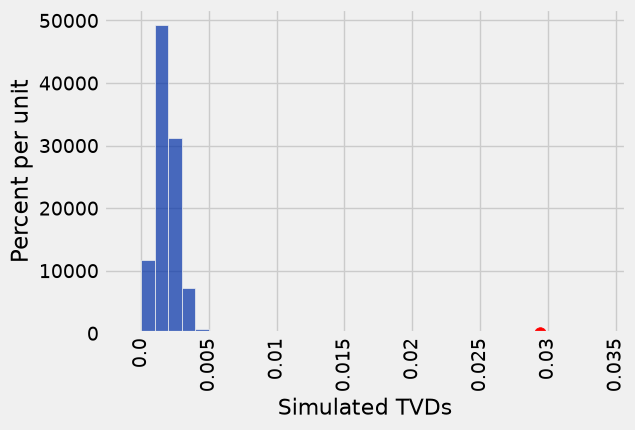

In [22]:
# Use this cell to generate your quantitative plot

def calculate_tvd(observed_dist, null_dist):
    return np.sum(abs(observed_dist - null_dist)) / 2

observed_tvd = calculate_tvd(observed_distribution, null_distribution)

simulated_tvds = make_array()
for i in np.arange(10000):
    one_sample = sample_proportions(sum(critical_by_borough.column('count')), null_distribution)
    sample_tvd = calculate_tvd(one_sample, null_distribution)
    simulated_tvds = np.append(simulated_tvds, sample_tvd)

Table().with_column('Simulated TVDs', simulated_tvds).hist('Simulated TVDs', bins=np.arange(-0.001, 0.035, 0.001))
plots.scatter(observed_tvd, 0.5, color='red', s=70, zorder=2);
plots.show();

*Replace this text with an analysis of your plot*

**Qualitative Plot:**

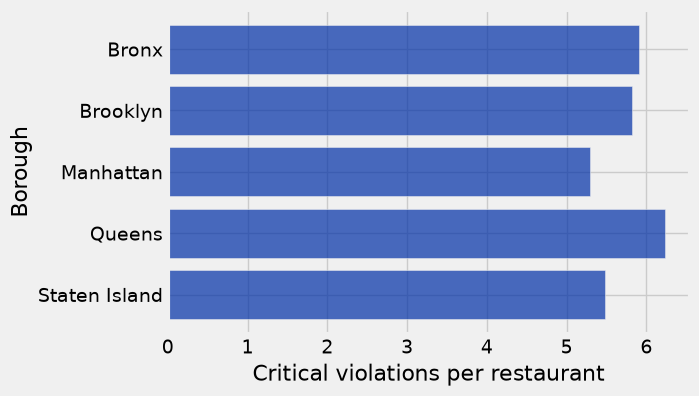

In [27]:
# Use this cell to generate your qualitative plot
critical_per_restaurant = critical_by_borough.column('count') / all_restaurants_by_borough.column('count')
Table().with_columns('Borough', all_restaurants_by_borough.column('BORO'),
                     'Critical violations per restaurant', critical_per_restaurant).barh('Borough')

*Replace this text with an analysis of your plot*

**Aggregated Data Table:**

In [28]:
# Use this cell to generate your aggregated data table
all_restaurants_by_borough = location_data.group('BORO')
null_distribution = all_restaurants_by_borough.column('count') / sum(all_restaurants_by_borough.column('count'))

critical_by_borough = violations_with_location.where('CRITICAL FLAG', are.equal_to('Critical')).group('BORO')
observed_distribution = critical_by_borough.column('count') / sum(critical_by_borough.column('count'))

all_restaurants_by_borough.show()
critical_by_borough.show()

BORO,count
Bronx,2332
Brooklyn,6832
Manhattan,10346
Queens,6041
Staten Island,992


BORO,count
Bronx,13769
Brooklyn,39773
Manhattan,54782
Queens,37649
Staten Island,5436


*Replace this text with an analysis of your plot*

**Table Requiring a Join Operation:**

In [9]:
# Use this cell to join two datasets
only_boroughs = location_data.select('restaurant_id', 'BORO')
violations_with_location = violation_data.join('restaurant_id', only_boroughs)
violations_with_location

restaurant_id,INSPECTION DATE,INSPECTION TYPE,VIOLATION CODE,CRITICAL FLAG,Community Board,Council District,BORO
30075445,02/03/2023,Cycle Inspection / Reopening Inspection,02G,Critical,211,13,Bronx
30075445,01/31/2023,Cycle Inspection / Initial Inspection,04H,Critical,211,13,Bronx
30075445,08/01/2023,Cycle Inspection / Initial Inspection,04L,Critical,211,13,Bronx
30075445,01/31/2023,Cycle Inspection / Initial Inspection,04L,Critical,211,13,Bronx
30075445,08/22/2023,Cycle Inspection / Re-inspection,04L,Critical,211,13,Bronx
30075445,01/31/2023,Cycle Inspection / Initial Inspection,04N,Critical,211,13,Bronx
30075445,08/01/2023,Cycle Inspection / Initial Inspection,05H,Critical,211,13,Bronx
30075445,11/08/2024,Cycle Inspection / Initial Inspection,06C,Critical,211,13,Bronx
30075445,01/31/2023,Cycle Inspection / Initial Inspection,06C,Critical,211,13,Bronx
30075445,01/31/2023,Cycle Inspection / Initial Inspection,06D,Critical,211,13,Bronx


*Replace this text with an analysis of your plot*

## Hypothesis Testing

**Do not copy code from demo notebooks or homeworks! You may split portions of your code into distinct cells. Also, be sure to
set a random seed so that your results are reproducible.**


**Remember, you may _not_ submit AI generated code or text. If you want to use anything that was not covered in this course, you MUST include text explaining where you have previously learned about it.**

In [ ]:
# set the random seed so that results are reproducible
random.seed(1231)

...

Ellipsis

## Prediction

**Be sure to set a random seed so that your results are reproducible.**

In [ ]:
# set the random seed so that results are reproducible
random.seed(1231)

...

Ellipsis

## Conclusion

*Replace this text with your conclusion*

## Peer Review

There are two parts of peer review:
1. A summary of each team member's contribution in the table below (discussed and submitted as a group)
2. Individual self-assessment and peer assessments from each team member, submitted via Google Forms (link available on Course Website)

We expect individual team members to take on different and complementary tasks. The percent breakdown in the table should be discussed as a team before final submission.

| Task | First Team Member Name | Second Team Member Name |
|:----:|:----------------------:|:-----------------------:|
|  Conceptualization of Questions for Analysis  |  %   |  %   |
|  Introduction: Writing  |  %   |  %   |
|  Exploratory Data Analysis: Quantiative Plot   |  %   |  %  |
|  Exploratory Data Analysis: Qualitative Plot   |  %   |  %  |
|  Exploratory Data Analysis: Aggregate & Join Tables   |  %   |  %  |
|  Exploratory Data Analysis: Writing   |  %   |  %  |
|  Hypothesis Testing: Implementation and Analysis   |  %   |  %  |
|  Hypothesis Testing: Writing   |  %   |  %  |
|  Prediction: Implementation and Analysis   |  %   |  %  |
|  Prediction: Writing   |  %   |  %  |
|  Conclusion: Writing   |  %   |  %  |

*Example table provided for reference (delete before final submission)*

| Task | Tiffany | Jennifer |
|:----:|:----------------------:|:-----------------------:|
|  Conceptualization of Questions for Analysis  |  50%   |  50%   |
|  Introduction: Writing  |  70%   |  30%   |
|  Exploratory Data Analysis: Quantiative Plot   |  90%   |  10%  |
|  Exploratory Data Analysis: Qualitative Plot   |  10%   |  90%  |
|  Exploratory Data Analysis: Aggregate & Join Tables   |  50%   |  50%  |
|  Exploratory Data Analysis: Writing   |  80%   |  20%  |
|  Hypothesis Testing: Implementation and Analysis   |  70%   |  30%  |
|  Hypothesis Testing: Writing   |  60%   |  40%  |
|  Prediction: Implementation and Analysis   |  30%   |  70%  |
|  Prediction: Writing   |  50%   |  50%  |
|  Conclusion: Writing   |  20%   | 80 %  |